# Napa Valley vintage prediction from review language

**Question:** Within reviews labeled `region_1 = "Napa Valley"`, can the language in the wine review `description` help distinguish a wine's vintage year?

This notebook deliberately uses **only `description` as the model input**. The `title` column is used only to extract the target vintage, never as a feature, because it often contains the answer directly. The analysis uses a transparent TF-IDF + logistic-regression model so we can inspect the terms most associated with each vintage.

> **Important limitation for a chronological project:** a classifier cannot predict a vintage class it has never seen in training. Therefore, the chronological section below tracks how a *closed-world* classifier changes as more yearly data become available. It is not a true forecast of a completely new vintage year.

In [1]:
%pip install pandas matplotlib seaborn scikit-learn

from pathlib import Path
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline

sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 120)
RANDOM_STATE = 42

  Using cached scikit_learn-1.9.1-cp313-cp313-win_amd64.whl.metadata (9.3 kB)
  Using cached scipy-1.18.1-cp313-cp313-win_amd64.whl.metadata (61 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached threadpoolctl-3.7.0-py3-none-any.whl.metadata (24 kB)
  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
Using cached scikit_learn-1.9.1-cp313-cp313-win_amd64.whl (8.2 MB)
Using cached joblib-1.6.0-py3-none-any.whl (306 kB)
Using cached cloudpickle-3.1.2-py3-none-any.whl (22 kB)
Using cached scipy-1.18.1-cp313-cp313-win_amd64.whl (36.6 MB)
Using cached threadpoolctl-3.7.0-py3-none-any.whl (26 kB)

   ------ --------------------------------- 1/6 [scipy]
   ------ --------------------------------- 1/6 [scipy]
   ------ --------------------------------- 1/6 [scipy]
   ------ --------------------------------- 1/6 [scipy]
   ------ --------------------------------- 1/6 [scipy]
   ------ --------------------------------- 1/6 [scipy]
   ------ ---------

## 1. Load data and reproduce the prior vintage-cleaning step

In [2]:
DATA_DIR = Path("datasets")

if not DATA_DIR.exists():
    raise FileNotFoundError(
        f"Could not find {DATA_DIR.resolve()}. Create a 'datasets' folder beside this notebook and place the Wine Reviews CSV there."
    )

csv_files = sorted(DATA_DIR.glob("*.csv"))
if not csv_files:
    raise FileNotFoundError(f"No CSV files found in {DATA_DIR.resolve()}.")

# Prefer the current Kaggle CSV that includes title/taster fields. Override if needed.
DATA_FILE = next((f for f in csv_files if "130k-v2" in f.name.lower()), csv_files[0])
print(f"Loading: {DATA_FILE}")

reviews = pd.read_csv(DATA_FILE)
reviews = reviews.drop(columns=[c for c in reviews.columns if c.lower().startswith("unnamed:")])

required_columns = {"title", "description", "region_1"}
missing_columns = required_columns - set(reviews.columns)
if missing_columns:
    raise KeyError(f"The dataset is missing required columns: {sorted(missing_columns)}")

print(f"Raw rows: {len(reviews):,}")

# A duplicate is the same title-and-description pair. Keep the first occurrence only.
# This happens before extracting the target, so a duplicate cannot affect any later counts or splits.
duplicate_reviews = reviews.duplicated(subset=["title", "description"]).sum()
reviews = reviews.drop_duplicates(subset=["title", "description"]).copy()

print(f"Duplicate title/description pairs removed: {duplicate_reviews:,}")
print(f"Rows after duplicate filtering: {len(reviews):,}")
reviews.head()

Loading: datasets\winemag-data-130k-v2.csv
Raw rows: 129,971
Duplicate title/description pairs removed: 9,983
Rows after duplicate filtering: 119,988


,country,description,designation,points,price,province,region_1,region_2,taster_name,taster_twitter_handle,title,variety,winery
0,Italy,"Aromas include tropical fruit, broom, brimstone and dried herb. The palate isn't overly expressive, offering unripen...",Vulkà Bianco,87,NaN,Sicily & Sardinia,Etna,NaN,Kerin O’Keefe,@kerinokeefe,Nicosia 2013 Vulkà Bianco (Etna),White Blend,Nicosia
1,Portugal,"This is ripe and fruity, a wine that is smooth while still structured. Firm tannins are filled out with juicy red be...",Avidagos,87,15.0,Douro,NaN,NaN,Roger Voss,@vossroger,Quinta dos Avidagos 2011 Avidagos Red (Douro),Portuguese Red,Quinta dos Avidagos
2,US,"Tart and snappy, the flavors of lime flesh and rind dominate. Some green pineapple pokes through, with crisp acidity...",NaN,87,14.0,Oregon,Willamette Valley,Willamette Valley,Paul Gregutt,@paulgwine,Rainstorm 2013 Pinot Gris (Willamette Valley),Pinot Gris,Rainstorm
3,US,"Pineapple rind, lemon pith and orange blossom start off the aromas. The palate is a bit more opulent, with notes of ...",Reserve Late Harvest,87,13.0,Michigan,Lake Michigan Shore,NaN,Alexander Peartree,NaN,St. Julian 2013 Reserve Late Harvest Riesling (Lake Michigan Shore),Riesling,St. Julian
4,US,"Much like the regular bottling from 2012, this comes across as rather rough and tannic, with rustic, earthy, herbal ...",Vintner's Reserve Wild Child Block,87,65.0,Oregon,Willamette Valley,Willamette Valley,Paul Gregutt,@paulgwine,Sweet Cheeks 2012 Vintner's Reserve Wild Child Block Pinot Noir (Willamette Valley),Pinot Noir,Sweet Cheeks


In [3]:
# Extract the first standalone four-digit vintage from title.
# This follows the prior notebook's approach and avoids digits embedded in longer numbers.
VINTAGE_PATTERN = r"(?<!\d)((?:18|19|20)\d{2})(?!\d)"
reviews["vintage"] = pd.to_numeric(
    reviews["title"].astype("string").str.extract(VINTAGE_PATTERN, expand=False),
    errors="coerce",
).astype("Int64")

print(f"Titles with an extracted vintage: {reviews['vintage'].notna().sum():,} / {len(reviews):,}")
reviews[["title", "vintage", "region_1"]].head(10)

Titles with an extracted vintage: 115,717 / 119,988


,title,vintage,region_1
0,Nicosia 2013 Vulkà Bianco (Etna),2013,Etna
1,Quinta dos Avidagos 2011 Avidagos Red (Douro),2011,NaN
2,Rainstorm 2013 Pinot Gris (Willamette Valley),2013,Willamette Valley
3,St. Julian 2013 Reserve Late Harvest Riesling (Lake Michigan Shore),2013,Lake Michigan Shore
4,Sweet Cheeks 2012 Vintner's Reserve Wild Child Block Pinot Noir (Willamette Valley),2012,Willamette Valley
5,Tandem 2011 Ars In Vitro Tempranillo-Merlot (Navarra),2011,Navarra
6,Terre di Giurfo 2013 Belsito Frappato (Vittoria),2013,Vittoria
7,Trimbach 2012 Gewurztraminer (Alsace),2012,Alsace
8,Heinz Eifel 2013 Shine Gewürztraminer (Rheinhessen),2013,NaN
9,Jean-Baptiste Adam 2012 Les Natures Pinot Gris (Alsace),2012,Alsace


## 2. Restrict to Napa Valley and build the modeling table

We keep one row per review with a non-missing description and extracted vintage. Year-like strings are removed from the review text before modeling so that a reviewer explicitly writing a year cannot leak the target to the model.

In [4]:
TARGET_REGION = "Napa Valley"

# Remove standalone years from description to prevent direct target leakage.
def clean_description(text):
    text = str(text)
    text = re.sub(VINTAGE_PATTERN, " ", text)
    return re.sub(r"\s+", " ", text).strip()

napa = reviews.loc[
    reviews["region_1"].eq(TARGET_REGION)
    & reviews["vintage"].notna()
    & reviews["description"].notna(),
    ["title", "description", "vintage", "variety", "points", "price", "taster_name"],
].copy()

napa["description_clean"] = napa["description"].map(clean_description)
napa = napa.loc[napa["description_clean"].str.len() > 0].copy()
napa["vintage"] = napa["vintage"].astype(int)

print(f"Napa Valley reviews with a usable vintage and description: {len(napa):,}")
print(f"Unique extracted vintages: {napa['vintage'].nunique():,}")
napa.head()

Napa Valley reviews with a usable vintage and description: 4,139
Unique extracted vintages: 24


,title,description,vintage,variety,points,price,taster_name,description_clean
10,Kirkland Signature 2011 Mountain Cuvée Cabernet Sauvignon (Napa Valley),"Soft, supple plum envelopes an oaky structure in this Cabernet, supported by 15% Merlot. Coffee and chocolate comple...",2011,Cabernet Sauvignon,87,19.0,Virginie Boone,"Soft, supple plum envelopes an oaky structure in this Cabernet, supported by 15% Merlot. Coffee and chocolate comple..."
55,RustRidge 2010 Estate Bottled Chardonnay (Napa Valley),"This shows jelly-like flavors of orange and pear, with some earthy tones. The mouthfeel is soft and there's a bounty...",2010,Chardonnay,85,30.0,NaN,"This shows jelly-like flavors of orange and pear, with some earthy tones. The mouthfeel is soft and there's a bounty..."
60,Okapi 2013 Estate Cabernet Sauvignon (Napa Valley),"Syrupy and dense, this wine is jammy in plum and vanilla, with indeterminate structure and plenty of oak. Ripe and f...",2013,Cabernet Sauvignon,86,100.0,Virginie Boone,"Syrupy and dense, this wine is jammy in plum and vanilla, with indeterminate structure and plenty of oak. Ripe and f..."
75,Mulvane Wine Co. 2013 The Cypher Red (Napa Valley),"This is made from equal parts Cabernet Franc and Merlot, with small additions of Malbec. Juicy, it reveals a raisiny...",2013,Bordeaux-style Red Blend,86,75.0,Virginie Boone,"This is made from equal parts Cabernet Franc and Merlot, with small additions of Malbec. Juicy, it reveals a raisiny..."
84,Napa Cellars 2014 Classic Zinfandel (Napa Valley),"A healthy addition of 13% Petite Sirah provides added weight and intensity to this wine, a soft, supple and richly c...",2014,Zinfandel,86,24.0,Virginie Boone,"A healthy addition of 13% Petite Sirah provides added weight and intensity to this wine, a soft, supple and richly c..."


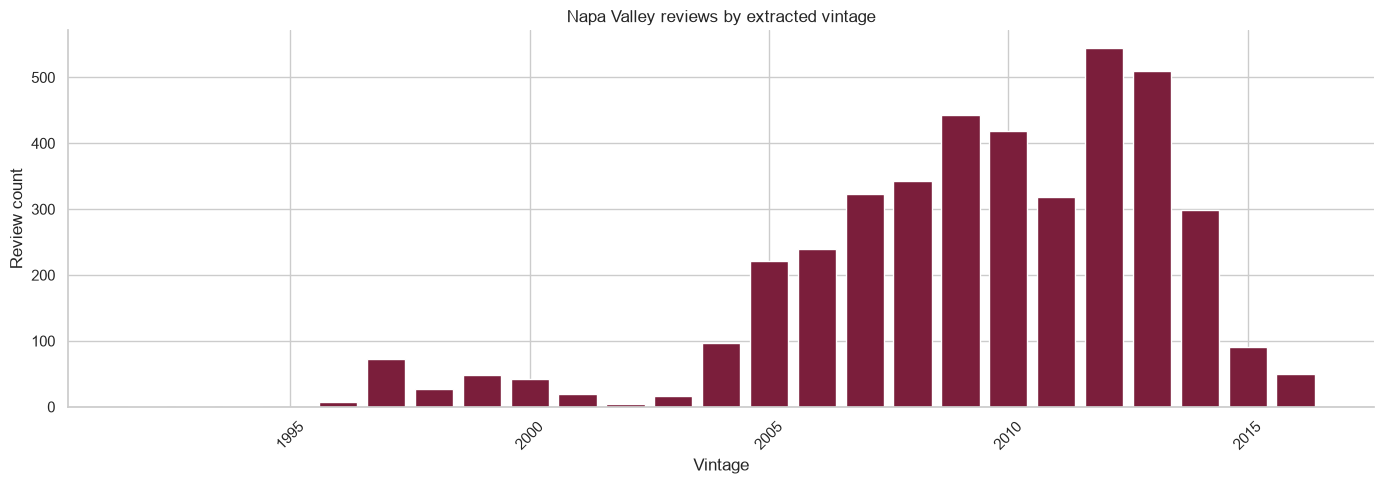

,review_count
vintage,
1992,1
1993,1
1994,2
1996,7
1997,72
1998,27
1999,49
2000,43
2001,20


In [5]:
vintage_counts = napa["vintage"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(14, 5))
ax.bar(vintage_counts.index, vintage_counts.values, color="#7b1e3b")
ax.set(title="Napa Valley reviews by extracted vintage", xlabel="Vintage", ylabel="Review count")
ax.tick_params(axis="x", rotation=45)
sns.despine()
plt.tight_layout()
plt.show()

vintage_counts.to_frame("review_count")

## 3. Select viable vintage classes

Vintage prediction is a multiclass problem. Very rare years cannot be reliably split into training and test examples, so this first model only retains years with at least `MIN_REVIEWS_PER_VINTAGE` reviews. Change the threshold after inspecting the counts above. Excluding sparse years is a modeling decision that should be reported.

In [6]:
MIN_REVIEWS_PER_VINTAGE = 75
eligible_vintages = vintage_counts[vintage_counts >= MIN_REVIEWS_PER_VINTAGE].index
model_data = napa.loc[napa["vintage"].isin(eligible_vintages)].copy()

print(f"Retained vintages ({len(eligible_vintages)}): {eligible_vintages.tolist()}")
print(f"Rows retained for the first model: {len(model_data):,} / {len(napa):,}")
model_data["vintage"].value_counts().sort_index().to_frame("review_count")

Retained vintages (12): [2004, 2005, 2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015]
Rows retained for the first model: 3,847 / 4,139


,review_count
vintage,
2004,97
2005,221
2006,239
2007,323
2008,342
2009,443
2010,419
2011,319
2012,544


## 4. Interpretable description-only classifier

The TF-IDF features represent words and two-word phrases. Multinomial logistic regression is a useful baseline because its coefficients can be inspected: positive coefficients indicate terms that push a review toward one particular vintage relative to the other retained vintages. This is association, not proof that the word was caused by the vintage.

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    model_data["description_clean"],
    model_data["vintage"],
    test_size=0.20,
    stratify=model_data["vintage"],
    random_state=RANDOM_STATE,
)

vintage_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=True,
        stop_words="english",
        ngram_range=(1, 2),
        min_df=2,
        max_df=0.95,
        sublinear_tf=True,
    )),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        C=1.0,
        random_state=RANDOM_STATE,
    )),
])

vintage_model.fit(X_train, y_train)
y_pred = vintage_model.predict(X_test)

majority_accuracy = y_test.value_counts(normalize=True).iloc[0]
print(f"Majority-class accuracy: {majority_accuracy:.3f}")
print(f"Model accuracy:          {accuracy_score(y_test, y_pred):.3f}")
print(f"Macro F1:                {f1_score(y_test, y_pred, average='macro'):.3f}")
print("\nPer-vintage results:")
print(classification_report(y_test, y_pred, zero_division=0))

Majority-class accuracy: 0.142
Model accuracy:          0.271
Macro F1:                0.263

Per-vintage results:
              precision    recall  f1-score   support

        2004       0.33      0.32      0.32        19
        2005       0.39      0.43      0.41        44
        2006       0.21      0.25      0.23        48
        2007       0.21      0.28      0.24        65
        2008       0.16      0.13      0.14        68
        2009       0.26      0.22      0.24        89
        2010       0.26      0.23      0.24        84
        2011       0.20      0.14      0.17        64
        2012       0.38      0.40      0.39       109
        2013       0.34      0.32      0.33       102
        2014       0.24      0.25      0.24        60
        2015       0.15      0.28      0.19        18

    accuracy                           0.27       770
   macro avg       0.26      0.27      0.26       770
weighted avg       0.27      0.27      0.27       770



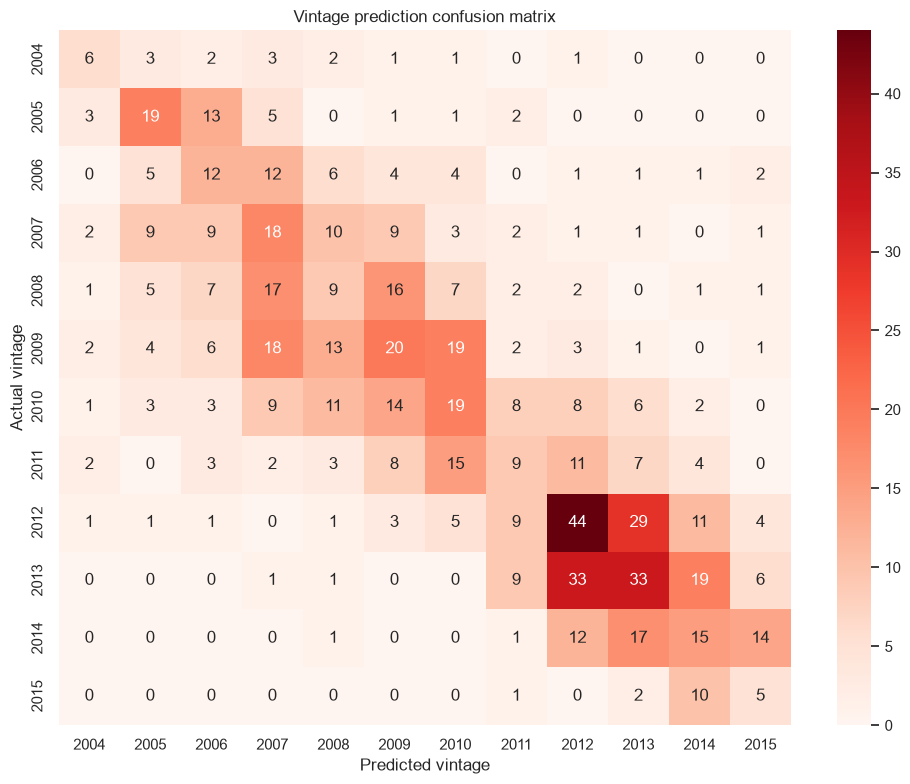

In [8]:
labels = np.sort(model_data["vintage"].unique())
cm = confusion_matrix(y_test, y_pred, labels=labels)

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Reds", xticklabels=labels, yticklabels=labels, ax=ax)
ax.set(title="Vintage prediction confusion matrix", xlabel="Predicted vintage", ylabel="Actual vintage")
plt.tight_layout()
plt.show()

## 5. Explain the language signals

For each predicted vintage, list the terms with the largest positive logistic-regression coefficients. Check these terms manually in their original review context before treating them as a story: they may reflect reviewer style, grape variety, winery, score, or sampling differences rather than an actual vintage effect.

In [9]:
def top_terms_by_vintage(fitted_pipeline, n_terms=15):
    vectorizer = fitted_pipeline.named_steps["tfidf"]
    classifier = fitted_pipeline.named_steps["classifier"]
    terms = np.array(vectorizer.get_feature_names_out())

    # scikit-learn stores one coefficient row for a binary classifier;
    # use opposite signs so that both classes can still be explained.
    coefficient_rows = classifier.coef_
    if len(classifier.classes_) == 2 and coefficient_rows.shape[0] == 1:
        coefficient_rows = np.vstack([-coefficient_rows[0], coefficient_rows[0]])

    rows = []
    for vintage, coefficients in zip(classifier.classes_, coefficient_rows):
        top_indices = coefficients.argsort()[-n_terms:][::-1]
        for rank, idx in enumerate(top_indices, start=1):
            rows.append({
                "vintage": vintage,
                "rank": rank,
                "term": terms[idx],
                "coefficient": coefficients[idx],
            })
    return pd.DataFrame(rows)

top_terms = top_terms_by_vintage(vintage_model, n_terms=15)
top_terms

,vintage,rank,term,coefficient
0,2004,1,04,3.228604
1,2004,2,cab,1.898911
2,2004,3,raisiny,1.565815
3,2004,4,hot,1.491495
4,2004,5,years,1.347759
...,...,...,...,...
175,2015,11,light,1.366598
176,2015,12,light bodied,1.337545
177,2015,13,strawberry,1.332303
178,2015,14,floral,1.283287


In [10]:
# Pick one vintage and inspect the review snippets containing its strongest terms.
VINTAGE_TO_INSPECT = int(labels[-1])
terms_to_inspect = top_terms.query("vintage == @VINTAGE_TO_INSPECT")["term"].head(5).tolist()
pattern = "|".join(re.escape(term) for term in terms_to_inspect)

print(f"Top terms for {VINTAGE_TO_INSPECT}: {terms_to_inspect}")
model_data.loc[
    (model_data["vintage"] == VINTAGE_TO_INSPECT)
    & model_data["description_clean"].str.contains(pattern, case=False, regex=True),
    ["title", "vintage", "variety", "points", "description"],
].head(10)

Top terms for 2015: ['white', 'lemon', 'pear', 'bodied', 'apple']


,title,vintage,variety,points,description
218,Robert Mondavi 2015 Fumé Blanc (Napa Valley),2015,Fumé Blanc,90,"Pithy, with grapefruit and lemon peel flavors, this wine is deceptively crisp and light on the nose, offering a weal..."
1637,Ca' Momi 2015 Chardonnay (Napa Valley),2015,Chardonnay,85,"Full and ripe, this wine offers thick meaty flavors of pineapple and peach, finishing in sweet vanilla oak."
2740,Black Stallion 2015 Sauvignon Blanc (Napa Valley),2015,Sauvignon Blanc,86,"This aromatic, medium-bodied white flirts with a distinct grassiness that can overwhelm, before settling into finer ..."
12837,Rombauer 2015 Sauvignon Blanc (Napa Valley),2015,Sauvignon Blanc,88,"Youthfully exuberant in fresh-squeezed grapefruit, lemon and lime, this wine has zesty acidity and pillows of vanill..."
13904,Starmont 2015 Sauvignon Blanc (Napa Valley),2015,Sauvignon Blanc,91,"A dash of Sémillon adds to the playfulness of this wine, which is medium-built and moderate-to-high in acidity. Tang..."
14330,Grgich Hills 2015 Essence Miljenko's Selection Estate Grown Sauvignon Blanc (Napa Valley),2015,Sauvignon Blanc,92,"A beautifully rich and rewarding expression of tropical fruit and creamy texture, this estate white spends nine mont..."
15128,Jax 2015 Y3 Chardonnay (Napa Valley),2015,Chardonnay,93,"This is a remarkable effort at the price, the wine sourced from Beckstoffer-owned sites in Carneros. Apple, peach an..."
15901,Oberon 2015 Sauvignon Blanc (Napa Valley),2015,Sauvignon Blanc,88,"Both cold-tank fermented and barrel-fermented, this white shows steely aromas of lemon and fresh lime, its acidity b..."
15919,Beringer 2015 Private Reserve Chardonnay (Napa Valley),2015,Chardonnay,88,"Sourced from the Gamble Ranch in Oakville, this is a fleshy, full-figured wine, floral in honeysuckle and voluptuous..."
17041,Peace Water 2015 Bliss Sauvignon Blanc (Napa Valley),2015,Sauvignon Blanc,90,"Fuzzy peach with a companionable co-host of Meyer lemon star in this medium-bodied, voluptuously appealing wine. It'..."


## 6. Paso Robles chronological expansion diagnostic

As a proxy for increasingly available data, this fits the same description-only workflow using all eligible Napa data through each cutoff year. It evaluates a stratified holdout *within* those known classes, so each step answers: **as Winetitude accumulates more vintage data, how well can it distinguish the vintages already observed?**

Do not describe this as predicting a genuinely unseen next-year vintage: that target label is absent from the training set.

In [11]:
def evaluate_through_year(data, cutoff, min_per_class=30):
    subset = data.loc[data["vintage"] <= cutoff].copy()
    counts = subset["vintage"].value_counts()
    subset = subset.loc[subset["vintage"].isin(counts[counts >= min_per_class].index)]

    if subset["vintage"].nunique() < 2:
        return None

    X_tr, X_te, y_tr, y_te = train_test_split(
        subset["description_clean"], subset["vintage"],
        test_size=0.20, stratify=subset["vintage"], random_state=RANDOM_STATE,
    )
    model = Pipeline([
        ("tfidf", TfidfVectorizer(stop_words="english", ngram_range=(1, 2), min_df=2, max_df=0.95)),
        ("classifier", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE)),
    ])
    model.fit(X_tr, y_tr)
    prediction = model.predict(X_te)
    return {
        "cutoff_year": cutoff,
        "rows": len(subset),
        "vintage_classes": subset["vintage"].nunique(),
        "accuracy": accuracy_score(y_te, prediction),
        "macro_f1": f1_score(y_te, prediction, average="macro"),
    }

chronology_results = [
    result for year in sorted(model_data["vintage"].unique())
    if (result := evaluate_through_year(model_data, year)) is not None
]
chronology = pd.DataFrame(chronology_results)
chronology

,cutoff_year,rows,vintage_classes,accuracy,macro_f1
0,2005,318,2,0.765625,0.723423
1,2006,557,3,0.544643,0.533333
2,2007,880,4,0.414773,0.407336
3,2008,1222,5,0.330612,0.337758
4,2009,1665,6,0.321321,0.327147
5,2010,2084,7,0.292566,0.303550
6,2011,2403,8,0.288981,0.299893
7,2012,2947,9,0.337288,0.312679
8,2013,3457,10,0.326590,0.307556
9,2014,3756,11,0.293883,0.289088


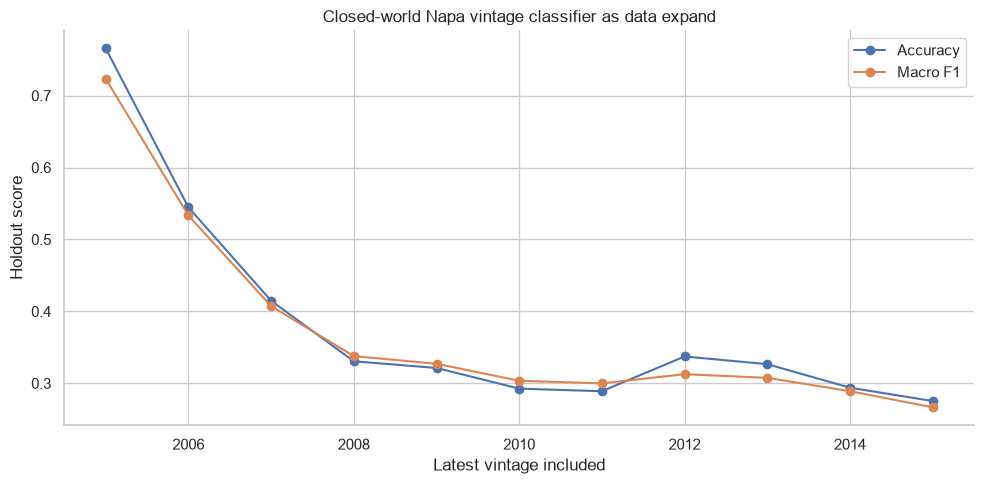

In [12]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(chronology["cutoff_year"], chronology["accuracy"], marker="o", label="Accuracy")
ax.plot(chronology["cutoff_year"], chronology["macro_f1"], marker="o", label="Macro F1")
ax.set(title="Closed-world Napa vintage classifier as data expand", xlabel="Latest vintage included", ylabel="Holdout score")
ax.legend()
sns.despine()
plt.tight_layout()
plt.show()

## 7. Exploratory Analysis

In [42]:
for i in range(2004, 2016):
    VINTAGE_TO_VIEW = i
    display(
        top_terms.loc[
            top_terms["vintage"] == VINTAGE_TO_VIEW,
            ["vintage", "rank", "term", "coefficient"]
        ]
    )

,vintage,rank,term,coefficient
0,2004,1,04,3.228604
1,2004,2,cab,1.898911
2,2004,3,raisiny,1.565815
3,2004,4,hot,1.491495
4,2004,5,years,1.347759
5,2004,6,previous,1.330823
6,2004,7,cabs,1.260803
7,2004,8,smooth,1.258846
8,2004,9,03,1.238540
9,2004,10,cherries,1.207051


,vintage,rank,term,coefficient
15,2005,1,cab,2.197607
16,2005,2,05,1.928656
17,2005,3,fine,1.818329
18,2005,4,currants,1.670827
19,2005,5,flavors,1.580409
20,2005,6,ripe,1.388139
21,2005,7,best,1.343354
22,2005,8,currant,1.330932
23,2005,9,cherries,1.240884
24,2005,10,structure,1.217872


,vintage,rank,term,coefficient
30,2006,1,blackberries,1.706738
31,2006,2,06,1.630096
32,2006,3,flavors blackberries,1.503646
33,2006,4,shows,1.373416
34,2006,5,rich,1.322072
35,2006,6,dry,1.298674
36,2006,7,flavors,1.294669
37,2006,8,currants,1.274293
38,2006,9,elegant,1.253687
39,2006,10,black currants,1.191902


,vintage,rank,term,coefficient
45,2007,1,blackberries,1.926700
46,2007,2,blackberries black,1.490917
47,2007,3,dry,1.435417
48,2007,4,cherries,1.406079
49,2007,5,sweet,1.225160
50,2007,6,tannins,1.164207
51,2007,7,blackberry,1.089066
52,2007,8,flavors,1.060191
53,2007,9,develop,1.046822
54,2007,10,blackberry cherry,0.946203


,vintage,rank,term,coefficient
60,2008,1,drink,1.710497
61,2008,2,rich,1.570929
62,2008,3,lots,1.465959
63,2008,4,years,1.337974
64,2008,5,delicious,1.280881
65,2008,6,sweet,1.242759
66,2008,7,flavors,1.148151
67,2008,8,dry,1.114988
68,2008,9,drinking,1.098408
69,2008,10,blackberry cherry,0.993280


...

,vintage,rank,term,coefficient
105,2011,1,herb,1.219565
106,2011,2,herbal,1.180421
107,2011,3,red,1.040602
108,2011,4,finish,1.025935
109,2011,5,peppercorn,1.015403
110,2011,6,tropical,0.946628
111,2011,7,tropical fruit,0.946256
112,2011,8,vintage,0.836070
113,2011,9,cranberry,0.823637
114,2011,10,citrus,0.820857


,vintage,rank,term,coefficient
120,2012,1,juicy,1.630033
121,2012,2,finish,1.320530
122,2012,3,plum,1.174116
123,2012,4,finishing,1.126206
124,2012,5,cabernet franc,1.037121
125,2012,6,leather,1.006975
126,2012,7,tar,0.971682
127,2012,8,tannin,0.949523
128,2012,9,wine offers,0.919631
129,2012,10,offers,0.916732


,vintage,rank,term,coefficient
135,2013,1,tannin,2.328458
136,2013,2,bodied,1.978611
137,2013,3,palate,1.266099
138,2013,4,bodied wine,1.186247
139,2013,5,clove,1.109114
140,2013,6,mix,1.054574
141,2013,7,savory,1.040675
142,2013,8,leathery,1.008357
143,2013,9,wine,0.992839
144,2013,10,dense,0.957769


,vintage,rank,term,coefficient
150,2014,1,bodied,1.971482
151,2014,2,tannin,1.390809
152,2014,3,round,1.381582
153,2014,4,light,1.370344
154,2014,5,apple,1.363450
155,2014,6,white,1.355312
156,2014,7,fresh,1.324417
157,2014,8,bold,1.273308
158,2014,9,wine,1.155051
159,2014,10,baked,1.144270


,vintage,rank,term,coefficient
165,2015,1,white,2.632810
166,2015,2,lemon,2.440717
167,2015,3,pear,2.390517
168,2015,4,bodied,2.045252
169,2015,5,apple,1.926687
170,2015,6,peach,1.925414
171,2015,7,palate,1.635361
172,2015,8,medium bodied,1.589250
173,2015,9,melon,1.393741
174,2015,10,steely,1.386333


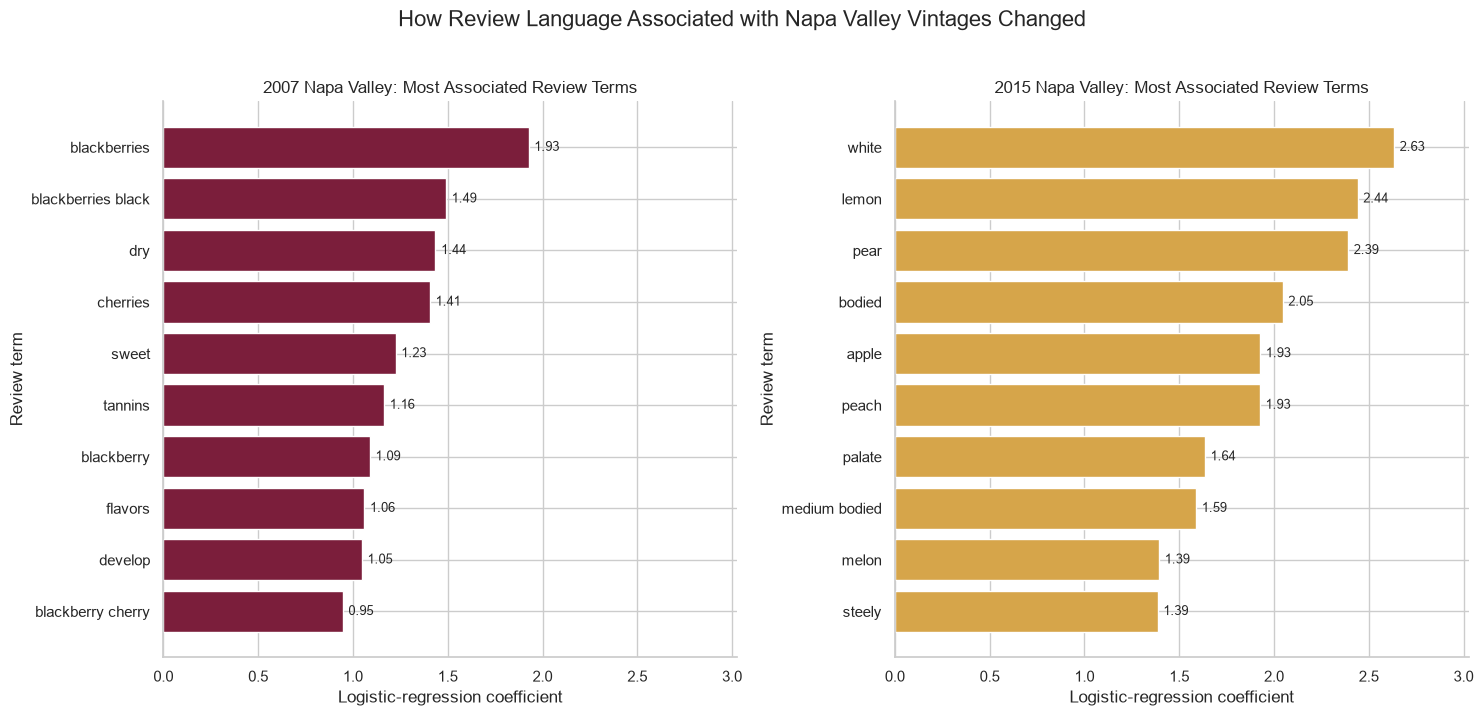

In [67]:
# Compare the strongest language signals for Napa Valley 2007 vs. 2015
YEARS_TO_COMPARE = [2007, 2015]
TERMS_TO_SHOW = 10

comparison_terms = (
    top_terms.loc[top_terms["vintage"].isin(YEARS_TO_COMPARE)]
    .sort_values(["vintage", "rank"])
    .groupby("vintage")
    .head(TERMS_TO_SHOW)
    .copy()
)

# Use one shared x-axis so the coefficient sizes are visually comparable
max_coefficient = comparison_terms["coefficient"].max() * 1.15

colors = {
    2007: "#7b1e3b",  # deep wine red
    2015: "#d6a54a",  # golden/white-wine tone
}

fig, axes = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(15, 7),
    sharex=True,
)

for ax, year in zip(axes, YEARS_TO_COMPARE):
    year_terms = (
        comparison_terms.loc[comparison_terms["vintage"] == year]
        .sort_values("coefficient", ascending=True)
    )

    ax.barh(
        year_terms["term"],
        year_terms["coefficient"],
        color=colors[year],
    )

    # Add coefficient labels at the end of each bar
    for term, coefficient in zip(
        year_terms["term"],
        year_terms["coefficient"],
    ):
        ax.text(
            coefficient + 0.03,
            term,
            f"{coefficient:.2f}",
            va="center",
            fontsize=9,
        )

    ax.set(
        title=f"{year} Napa Valley: Most Associated Review Terms",
        xlabel="Logistic-regression coefficient",
        ylabel="Review term",
        xlim=(0, max_coefficient),
    )

    sns.despine(ax=ax)

fig.suptitle(
    "How Review Language Associated with Napa Valley Vintages Changed",
    fontsize=16,
    y=1.02,
)

plt.tight_layout()
plt.show()

In [43]:
# Top five varieties represented in each vintage
top_varieties_by_vintage = (
    model_data.groupby(["vintage", "variety"])
    .size()
    .rename("review_count")
    .reset_index()
    .sort_values(["vintage", "review_count"], ascending=[True, False])
    .groupby("vintage")
    .head(5)
)

top_varieties_by_vintage

,vintage,variety,review_count
2,2004,Cabernet Sauvignon,48
5,2004,Merlot,18
0,2004,Bordeaux-style Red Blend,10
12,2004,Syrah,5
13,2004,Zinfandel,3
16,2005,Cabernet Sauvignon,108
20,2005,Merlot,31
14,2005,Bordeaux-style Red Blend,26
24,2005,Red Blend,12
29,2005,Syrah,12


In [44]:
# Percentage of each vintage represented by each variety
variety_share_by_vintage = pd.crosstab(
    model_data["vintage"],
    model_data["variety"],
    normalize="index"
) * 100

# Restrict display to the 10 most common varieties overall
top_10_varieties = model_data["variety"].value_counts().head(10).index

variety_share_by_vintage[top_10_varieties].round(1)

variety,Cabernet Sauvignon,Chardonnay,Merlot,Bordeaux-style Red Blend,Sauvignon Blanc,Red Blend,Zinfandel,Syrah,Cabernet Franc,Petite Sirah
vintage,,,,,,,,,,
2004,49.5,2.1,18.6,10.3,0.0,2.1,3.1,5.2,2.1,1.0
2005,48.9,3.6,14.0,11.8,0.9,5.4,3.2,5.4,0.5,0.9
2006,43.1,7.9,10.0,10.0,5.4,3.3,5.9,2.9,0.4,2.1
2007,45.2,5.6,11.8,9.3,4.6,5.3,5.0,1.2,2.2,1.9
2008,44.4,7.3,8.5,7.0,5.6,5.8,3.5,2.0,2.0,3.2
2009,45.1,6.1,6.1,6.5,7.0,7.4,3.8,3.2,2.3,1.8
2010,41.5,10.7,8.1,7.2,6.7,6.2,2.4,2.6,2.1,3.1
2011,39.2,9.1,6.0,8.2,8.2,5.6,4.1,2.5,2.8,0.3
2012,41.4,8.3,7.0,7.0,6.2,8.5,2.9,2.4,2.2,1.3


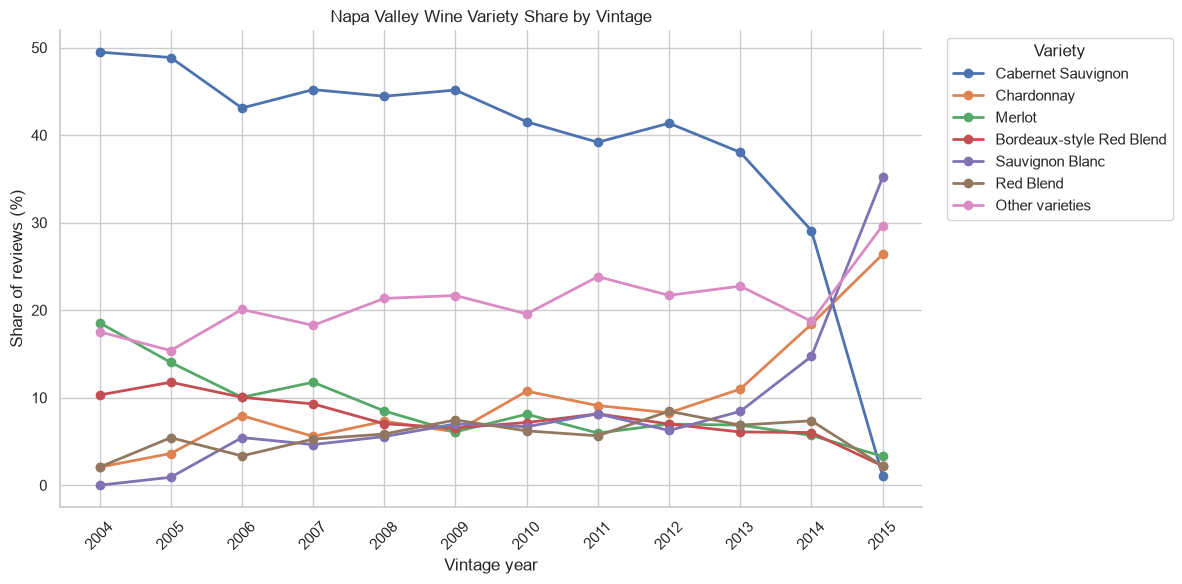

In [64]:
# Share of Napa Valley wine varieties across the vintages used in the model
TOP_N = 6

# Identify the most common varieties across all analyzed Napa reviews
top_varieties = model_data["variety"].value_counts().head(TOP_N).index

# Count varieties within each vintage, then convert counts to percentages
variety_share = (
    pd.crosstab(model_data["vintage"], model_data["variety"])
    .div(
        pd.crosstab(model_data["vintage"], model_data["variety"]).sum(axis=1),
        axis=0,
    )
    * 100
)

# Keep the leading varieties and combine every other variety into one category
plot_data = variety_share.reindex(columns=top_varieties, fill_value=0).copy()
plot_data["Other varieties"] = 100 - plot_data.sum(axis=1)

# Create the line chart
fig, ax = plt.subplots(figsize=(12, 6))

for variety in plot_data.columns:
    ax.plot(
        plot_data.index,
        plot_data[variety],
        marker="o",
        linewidth=2,
        label=variety,
    )

ax.set(
    title="Napa Valley Wine Variety Share by Vintage",
    xlabel="Vintage year",
    ylabel="Share of reviews (%)",
)

ax.set_xticks(plot_data.index)
ax.tick_params(axis="x", rotation=45)
ax.legend(title="Variety", bbox_to_anchor=(1.02, 1), loc="upper left")
sns.despine()
plt.tight_layout()
plt.show()

For Napa Valley, variety in wine changes over time, changing the flavor highlighted in the reviews. This seems to effect the predictions of the model, which is better than the baseline accuracy of predicting solely the majority class. The confustion matrix from earlier in the notebook highlights how the model does well at predicting at least close to the true vintage, showing how the flavors are changing over time and are similar across similar years. I will now look into seeing if this holds for other regions.

## 8. Seeing if these findings hold across other regions

In [46]:
def run_region_vintage_model(
    region=None,
    min_reviews_per_vintage=75,
    test_size=0.20,
    random_state=42,
):
    """
    Train an interpretable vintage classifier for one region_1 value.
    Set region=None to use all regions together.
    """

    # Select either one region or the full dataset
    subset = reviews.loc[
        reviews["vintage"].notna()
        & reviews["description"].notna()
    ].copy()

    if region is not None:
        subset = subset.loc[subset["region_1"] == region].copy()
        scope_name = region
    else:
        scope_name = "All regions"

    subset["vintage"] = subset["vintage"].astype(int)

    # Keep only vintages with enough reviews for a train/test split
    vintage_counts = subset["vintage"].value_counts().sort_index()
    eligible_vintages = vintage_counts[
        vintage_counts >= min_reviews_per_vintage
    ].index

    subset = subset.loc[subset["vintage"].isin(eligible_vintages)].copy()

    if subset["vintage"].nunique() < 2:
        print(f"Not enough eligible vintage classes for {scope_name}.")
        return None

    # Remove full years and short year tokens, such as 04 or '04
    suffixes = "|".join(
        f"{int(year) % 100:02d}"
        for year in eligible_vintages
    )

    full_year_pattern = r"(?<!\d)(?:18|19|20)\d{2}(?!\d)"
    short_year_pattern = rf"(?<!\d)(?:['’]\s*)?(?:{suffixes})(?!\d)"

    subset["description_model"] = (
        subset["description"]
        .astype(str)
        .str.replace(full_year_pattern, " ", regex=True)
        .str.replace(short_year_pattern, " ", regex=True)
        .str.replace(r"\s+", " ", regex=True)
        .str.strip()
    )

    X_train, X_test, y_train, y_test = train_test_split(
        subset["description_model"],
        subset["vintage"],
        test_size=test_size,
        stratify=subset["vintage"],
        random_state=random_state,
    )

    model = Pipeline([
        (
            "tfidf",
            TfidfVectorizer(
                lowercase=True,
                stop_words="english",
                ngram_range=(1, 2),
                min_df=2,
                max_df=0.95,
                sublinear_tf=True,
            ),
        ),
        (
            "classifier",
            LogisticRegression(
                max_iter=2000,
                class_weight="balanced",
                C=1.0,
                random_state=random_state,
            ),
        ),
    ])

    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    majority_year = y_train.mode()[0]

    metrics = {
        "region": scope_name,
        "rows": len(subset),
        "vintage_classes": subset["vintage"].nunique(),
        "majority_accuracy": y_test.value_counts(normalize=True).iloc[0],
        "accuracy": accuracy_score(y_test, y_pred),
        "accuracy_lift": (
            accuracy_score(y_test, y_pred)
            - y_test.value_counts(normalize=True).iloc[0]
        ),
        "macro_f1": f1_score(y_test, y_pred, average="macro"),
        # This checks whether predictions are numerically near the true year.
        "mean_year_error": np.mean(np.abs(y_test - y_pred)),
        "majority_mean_year_error": np.mean(
            np.abs(y_test - majority_year)
        ),
    }

    return {
        "data": subset,
        "counts": subset["vintage"].value_counts().sort_index(),
        "model": model,
        "X_test": X_test,
        "y_test": y_test,
        "y_pred": y_pred,
        "metrics": metrics,
    }

In [47]:
columbia_results = run_region_vintage_model(
    region="Columbia Valley (WA)",
    min_reviews_per_vintage=75,
)

pd.Series(columbia_results["metrics"])

region                      Columbia Valley (WA)
rows                                        3572
vintage_classes                               11
majority_accuracy                       0.152448
accuracy                                0.303497
accuracy_lift                           0.151049
macro_f1                                 0.28674
mean_year_error                         1.341259
majority_mean_year_error                2.335664
dtype: object

In [48]:
# Vintage distribution for Columbia Valley
columbia_results["counts"].to_frame("review_count")

,review_count
vintage,
2005,138
2006,186
2007,224
2008,278
2009,355
2010,357
2011,416
2012,545
2013,499


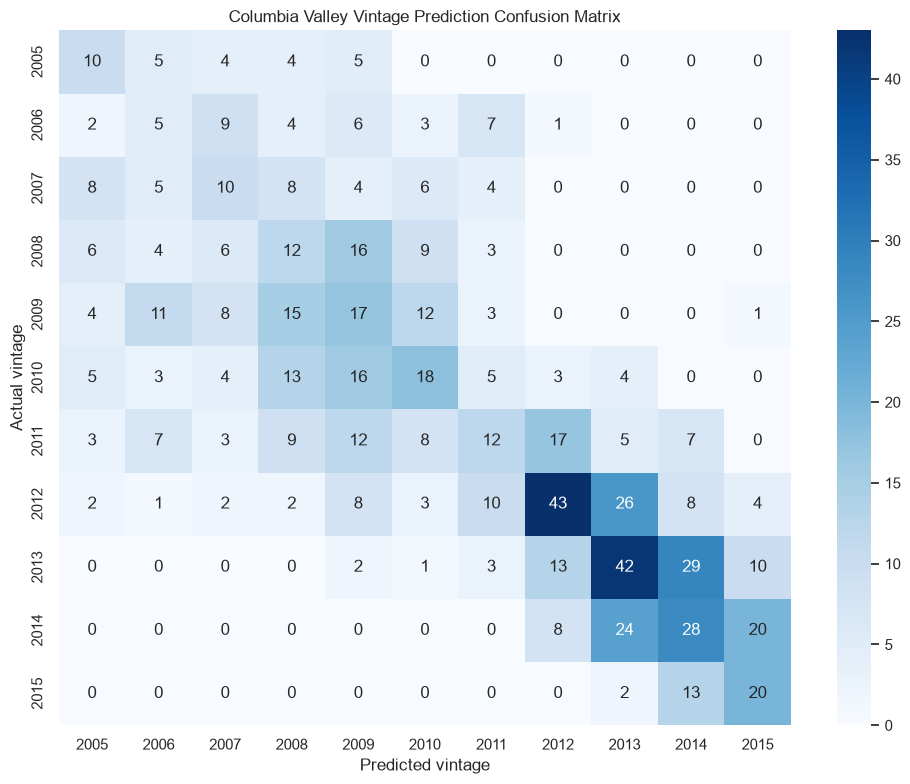

In [49]:
# Confusion matrix for Columbia Valley
labels = np.sort(columbia_results["data"]["vintage"].unique())

cm = confusion_matrix(
    columbia_results["y_test"],
    columbia_results["y_pred"],
    labels=labels,
)

fig, ax = plt.subplots(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels,
    ax=ax,
)

ax.set(
    title="Columbia Valley Vintage Prediction Confusion Matrix",
    xlabel="Predicted vintage",
    ylabel="Actual vintage",
)

plt.tight_layout()
plt.show()

In [55]:
# Top terms associated with each Columbia Valley vintage
columbia_top_terms = top_terms_by_vintage(
    columbia_results["model"],
    n_terms=15,
)
with pd.option_context(
    "display.max_rows", None, "display.max_columns", None
):
    display(columbia_top_terms.sort_values(["vintage", "rank"]))

,vintage,rank,term,coefficient
0,2005,1,acids,2.426976
1,2005,2,chocolaty,1.672646
2,2005,3,berry,1.564942
3,2005,4,washington,1.541225
4,2005,5,stemmy,1.422444
5,2005,6,generic,1.364841
6,2005,7,mixed,1.356183
7,2005,8,cab,1.201252
8,2005,9,hints,1.186398
9,2005,10,grapes,1.173019


In [51]:
columbia_top_varieties = (
    columbia_results["data"]
    .groupby(["vintage", "variety"])
    .size()
    .rename("review_count")
    .reset_index()
    .sort_values(["vintage", "review_count"], ascending=[True, False])
    .groupby("vintage")
    .head(5)
)

columbia_top_varieties

,vintage,variety,review_count
12,2005,Red Blend,36
17,2005,Syrah,24
4,2005,Cabernet Sauvignon,23
9,2005,Merlot,21
2,2005,Cabernet Franc,5
36,2006,Red Blend,36
24,2006,Cabernet Sauvignon,23
42,2006,Syrah,22
25,2006,Chardonnay,19
32,2006,Merlot,17


In [52]:
all_regions_results = run_region_vintage_model(
    region=None,
    min_reviews_per_vintage=150,
)

pd.Series(all_regions_results["metrics"])

region                      All regions
rows                             115350
vintage_classes                      20
majority_accuracy              0.124361
accuracy                       0.240919
accuracy_lift                  0.116558
macro_f1                       0.196427
mean_year_error                2.286649
majority_mean_year_error       2.802601
dtype: object

Across both Napa Valley and Columbia Valley, review text predicts vintage better than a majority-class baseline, and errors often fall on nearby years. However, the associated language is partly explained by changing varietal composition across vintages, meaning the model captures both vintage-related review patterns and shifts in which wines were reviewed each year.

Vintage prediction from review text generalizes beyond Napa Valley: both Napa and Columbia Valley show above-baseline prediction and mostly near-year errors. Yet the change in wine varieties reviewed over time is a major confounder, so the next modeling step is to hold variety constant—such as modeling Cabernet Sauvignon vintages only—to isolate language more plausibly attributable to vintage.